# Development of Predictive Models for Fetal Health
**DataLab Analytics Final Project** · Supervisor: Oyeleke Olayemi · Student: Sheriff Olalekan Ayoola

Cardiotocograms (CTGs) are cheap and widely available, but reading them correctly takes trained staff, which is scarce in low-resource settings. This notebook builds machine-learning models that classify a CTG recording as **Normal (1)**, **Suspect (2)** or **Pathological (3)**, to act as a decision-support tool.

## 1. Project Objectives, Expected Outcome and Performance Metrics

**Objective.** Build and compare classification models that predict `fetal_health` from CTG measurements, and deploy the best one as a Streamlit prototype that returns *probabilities* for each class.

**Expected outcome.** A reliable model that (a) rarely misses a Pathological case, (b) separates Normal from Suspect/Pathological well, and (c) is explained clearly enough for a clinician to trust.

**Performance metrics (classification).**
1. **Recall (sensitivity), especially for the Pathological class**. Missing a distressed fetus is the costliest error, so recall matters most.
2. **Macro F1-score**. Averages F1 over the three classes equally, so the rare Suspect and Pathological classes count as much as Normal. Plain accuracy would reward a model that mostly says "Normal".
3. **Macro Precision**. Shows how many alarms raised for each class are real (false alarms waste scarce clinical resources).
4. **ROC-AUC (one-vs-rest, macro)**. Threshold-independent measure of how well each class is separated from the others.
5. **Accuracy and the Confusion Matrix**. Reported for completeness and to see exactly *which* classes get confused.

In [1]:
import warnings, os; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, classification_report)
RS = 42
sns.set_theme(style="whitegrid")
os.makedirs("figs", exist_ok=True)
CLASS_NAMES = {1: "Normal", 2: "Suspect", 3: "Pathological"}

## 2. Data Preparation
### 2.1 Load and inspect the data

In [2]:
df = pd.read_csv("fetalhealth.csv")
print("Shape:", df.shape)
df.head()

Shape: (2126, 22)


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,mean_value_of_long_term_variability,histogram_width,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120,0.000,0.0,0.000,0.000,0.0,0.0,73,0.5,43,2.4,64,62,126,2,0,120,137,121,73,1,2
1,132,0.006,0.0,0.006,0.003,0.0,0.0,17,2.1,0,10.4,130,68,198,6,1,141,136,140,12,0,1
2,133,0.003,0.0,0.008,0.003,0.0,0.0,16,2.1,0,13.4,130,68,198,5,1,141,135,138,13,0,1
3,134,0.003,0.0,0.008,0.003,0.0,0.0,16,2.4,0,23.0,117,53,170,11,0,137,134,137,13,1,1
4,132,0.007,0.0,0.008,0.000,0.0,0.0,16,2.4,0,19.9,117,53,170,9,0,137,136,138,11,1,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   int64  
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         2126 non-null   int64  
 8   mean_value_of_short_term_variability             

### 2.2 Data-quality checks
I check column names/data types, missing values, duplicates, negative values, special characters and outliers.

In [4]:
# Tidy column names (spaces -> underscores) so they are safe to use in code
df.columns = [c.strip().replace(" ", "_") for c in df.columns]

print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Non-numeric columns:", [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])])
print("Special characters in column names:", [c for c in df.columns if not c.replace('_','').isalnum()])

neg = (df < 0).sum(); print("\nColumns with negative values:\n", neg[neg > 0])
print("\nUnique values in histogram_tendency:", [int(v) for v in sorted(df.histogram_tendency.unique())])

Missing values: 0
Duplicate rows: 13
Non-numeric columns: []
Special characters in column names: []

Columns with negative values:
 histogram_tendency    165
dtype: int64

Unique values in histogram_tendency: [-1, 0, 1]


**Findings.**
- **No missing values** and **all columns are numeric**, so no imputation or type conversion is needed. The checks were still carried out as required.
- **13 exact duplicate rows** exist. Duplicates would let identical records fall in both the train and test sets and inflate the scores, so they are removed.
- The only negative values are in `histogram_tendency` (-1 = falling, 0 = flat, 1 = rising). These are **valid category codes, not errors**, so they are kept.
- Column names contained spaces (`baseline value`); they were cleaned. The target is stored as integers 1/2/3 and is already numeric.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
df["fetal_health"] = df["fetal_health"].astype(int)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (2113, 22)


### 2.3 Encoding categorical features
There are **no text/categorical predictors**. `histogram_tendency` is already an ordinal numeric code (-1, 0, 1) and the target is already numeric (1, 2, 3), so no encoding is required.

### 2.4 Train/test split (before any fitting step)
To prevent data leakage, the data is split **first** (80/20, stratified so each class keeps its proportion). Outlier limits, the scaler, SMOTE and feature selection are all learned from the **training set only**.

In [6]:
X = df.drop(columns="fetal_health"); y = df["fetal_health"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1690, 21)  Test: (423, 21)


### 2.5 Outliers
I use the IQR rule to *detect* outliers, then **winsorise** (cap) only the continuous measurements at the 0.5th/99.5th percentile of the **training** data. Sparse event counts (accelerations, decelerations, contractions, movements) are mostly zero by nature, so their "outliers" are real clinical events and are **not** altered.

In [7]:
q1, q3 = X_train.quantile(.25), X_train.quantile(.75); iqr = q3 - q1
outliers = ((X_train < q1 - 1.5*iqr) | (X_train > q3 + 1.5*iqr)).sum().sort_values(ascending=False)
print("IQR-rule outlier counts (train):\n", outliers.head(8))

sparse = ["accelerations","fetal_movement","uterine_contractions","light_decelerations",
          "severe_decelerations","prolongued_decelerations","histogram_tendency","histogram_number_of_zeroes"]
cont = [c for c in X.columns if c not in sparse]
lo, hi = X_train[cont].quantile(0.005), X_train[cont].quantile(0.995)   # learned on TRAIN only
X_train = X_train.copy(); X_test = X_test.copy()
X_train[cont] = X_train[cont].clip(lo, hi, axis=1)
X_test[cont]  = X_test[cont].clip(lo, hi, axis=1)
print("\nWinsorised columns:", len(cont))

IQR-rule outlier counts (train):
 histogram_number_of_zeroes                                394
fetal_movement                                            254
percentage_of_time_with_abnormal_long_term_variability    247
prolongued_decelerations                                  148
histogram_variance                                        142
light_decelerations                                       109
histogram_mode                                             59
mean_value_of_long_term_variability                        56
dtype: int64

Winsorised columns: 13


## 3. Exploratory Data Analysis (EDA)

In [8]:
display_df = df.describe().T.round(3); display_df

,count,mean,std,min,25%,50%,75%,max
baseline_value,2113.0,133.305,9.837,106.0,126.000,133.000,140.000,160.000
accelerations,2113.0,0.003,0.004,0.0,0.000,0.002,0.006,0.019
fetal_movement,2113.0,0.010,0.047,0.0,0.000,0.000,0.003,0.481
uterine_contractions,2113.0,0.004,0.003,0.0,0.002,0.005,0.007,0.015
light_decelerations,2113.0,0.002,0.003,0.0,0.000,0.000,0.003,0.015
severe_decelerations,2113.0,0.000,0.000,0.0,0.000,0.000,0.000,0.001
prolongued_decelerations,2113.0,0.000,0.001,0.0,0.000,0.000,0.000,0.005
abnormal_short_term_variability,2113.0,46.994,17.178,12.0,32.000,49.000,61.000,87.000
mean_value_of_short_term_variability,2113.0,1.335,0.884,0.2,0.700,1.200,1.700,7.000
percentage_of_time_with_abnormal_long_term_variability,2113.0,9.795,18.337,0.0,0.000,0.000,11.000,91.000


**Interpretation.** The features sit on very different scales (e.g. `accelerations` ≈ 0.003 versus `histogram_mean` ≈ 135), which is why scaling is needed for Logistic Regression and KNN. The event-rate features (`severe_decelerations`, `prolongued_decelerations`, `light_decelerations`) are zero for most recordings, so they are highly skewed.

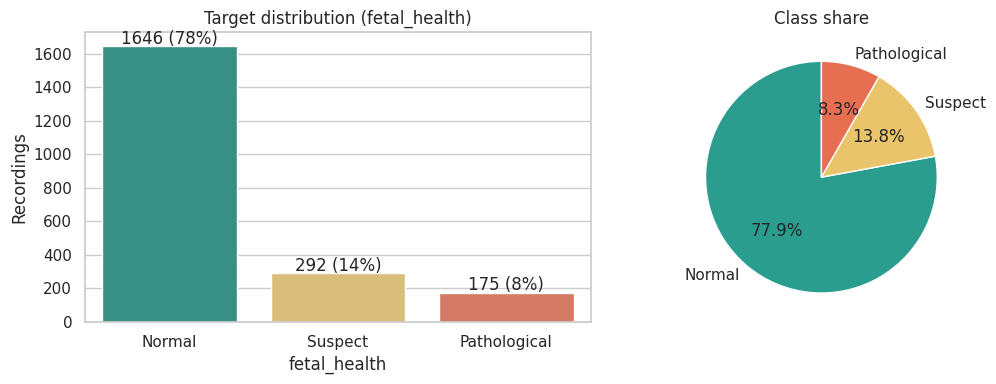

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
counts = y.map(CLASS_NAMES).value_counts().reindex(["Normal","Suspect","Pathological"])
sns.barplot(x=counts.index, y=counts.values, palette=["#2a9d8f","#e9c46a","#e76f51"], ax=ax[0])
for i, v in enumerate(counts.values): ax[0].text(i, v+15, f"{v} ({v/len(y):.0%})", ha="center")
ax[0].set_title("Target distribution (fetal_health)"); ax[0].set_ylabel("Recordings")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", colors=["#2a9d8f","#e9c46a","#e76f51"], startangle=90)
ax[1].set_title("Class share")
plt.tight_layout(); plt.savefig("figs/01_target_distribution.png", dpi=150); plt.show()

**Interpretation.** The target is clearly **imbalanced**: about 78% Normal, 14% Suspect and 8% Pathological. A model that always predicts "Normal" would be ~78% accurate yet useless clinically, so accuracy alone is misleading and the minority classes need to be handled (SMOTE, section 5).

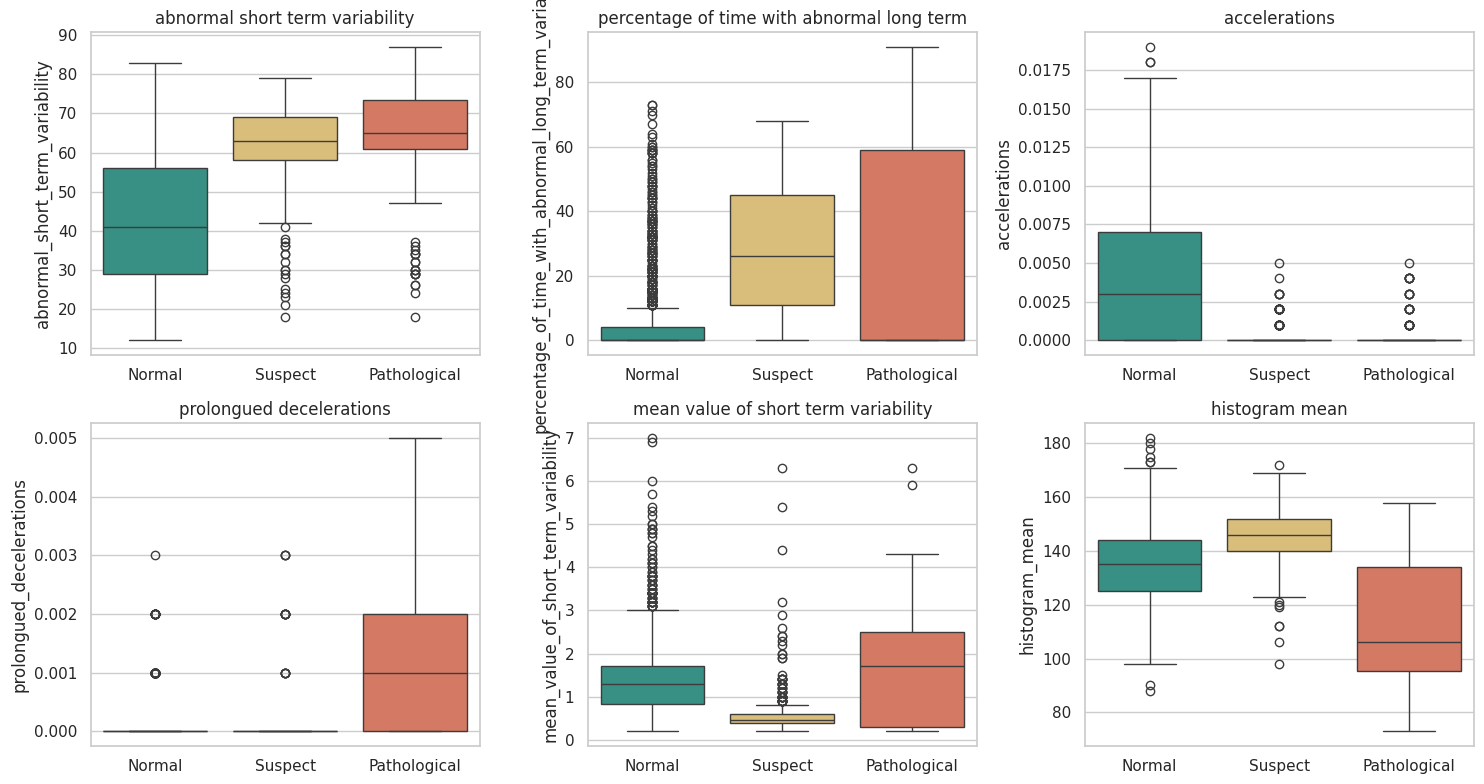

In [10]:
key = ["abnormal_short_term_variability","percentage_of_time_with_abnormal_long_term_variability",
       "accelerations","prolongued_decelerations","mean_value_of_short_term_variability","histogram_mean"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
plot_df = df.assign(Class=df.fetal_health.map(CLASS_NAMES))
for a, c in zip(axes.ravel(), key):
    sns.boxplot(data=plot_df, x="Class", y=c, order=["Normal","Suspect","Pathological"],
                palette=["#2a9d8f","#e9c46a","#e76f51"], ax=a)
    a.set_title(c.replace("_"," ")[:42]); a.set_xlabel("")
plt.tight_layout(); plt.savefig("figs/02_key_features_by_class.png", dpi=150); plt.show()

**Interpretation.**
- **Abnormal short-term variability (ASTV)** is clearly higher in Suspect (mean ≈ 62%) and Pathological (≈ 65%) recordings than in Normal ones (≈ 43%). The heart-rate pattern is more erratic when the fetus is under stress.
- **Percentage of time with abnormal long-term variability** averages only about 5% in Normal recordings versus about 29% (Suspect) and 23% (Pathological), so it also separates healthy from abnormal recordings.
- **Accelerations** (a good sign) appear in about 70% of Normal recordings but only about 16-17% of Suspect and Pathological ones. Their absence is a warning sign.
- **Prolonged decelerations** are almost absent in Normal/Suspect recordings but appear in about **54% of Pathological** recordings versus ~4–5% of the others, making them a very strong indicator of oxygen deprivation.

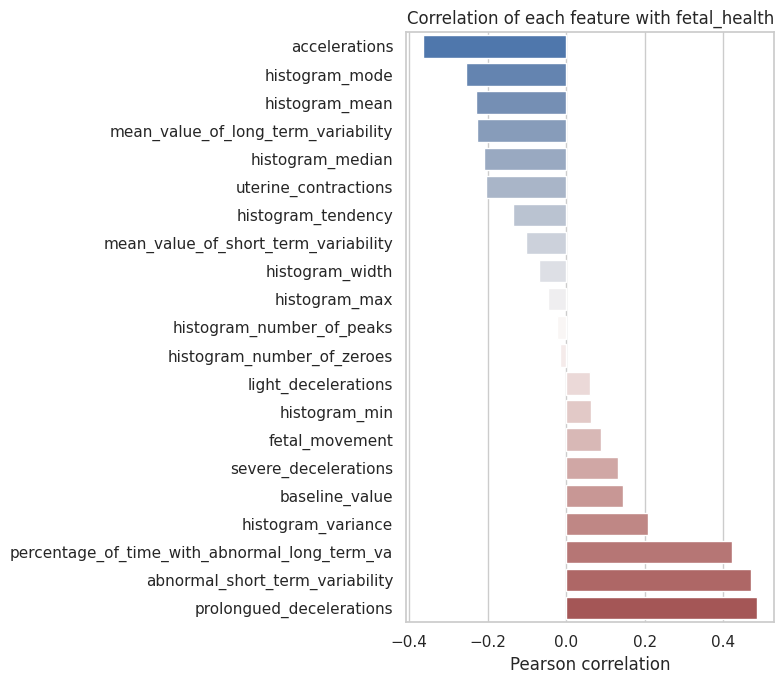

In [11]:
corr_t = df.corr()["fetal_health"].drop("fetal_health").sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(x=corr_t.values, y=[c[:45] for c in corr_t.index], palette="vlag", ax=ax)
ax.set_title("Correlation of each feature with fetal_health"); ax.set_xlabel("Pearson correlation")
plt.tight_layout(); plt.savefig("figs/03_corr_with_target.png", dpi=150); plt.show()

**Interpretation.** The strongest positive correlations with worse outcomes are `prolongued_decelerations` (0.49), `abnormal_short_term_variability` (0.47) and `percentage_of_time_with_abnormal_long_term_variability` (0.42). `accelerations` has the strongest negative correlation (-0.36): more accelerations mean a healthier fetus. These agree with the clinical meaning of the variables and guide feature selection.

histogram_mean   histogram_median    0.95
histogram_mode   histogram_median    0.93
histogram_width  histogram_min       0.90
histogram_mode   histogram_mean      0.89
baseline_value   histogram_median    0.79
dtype: float64


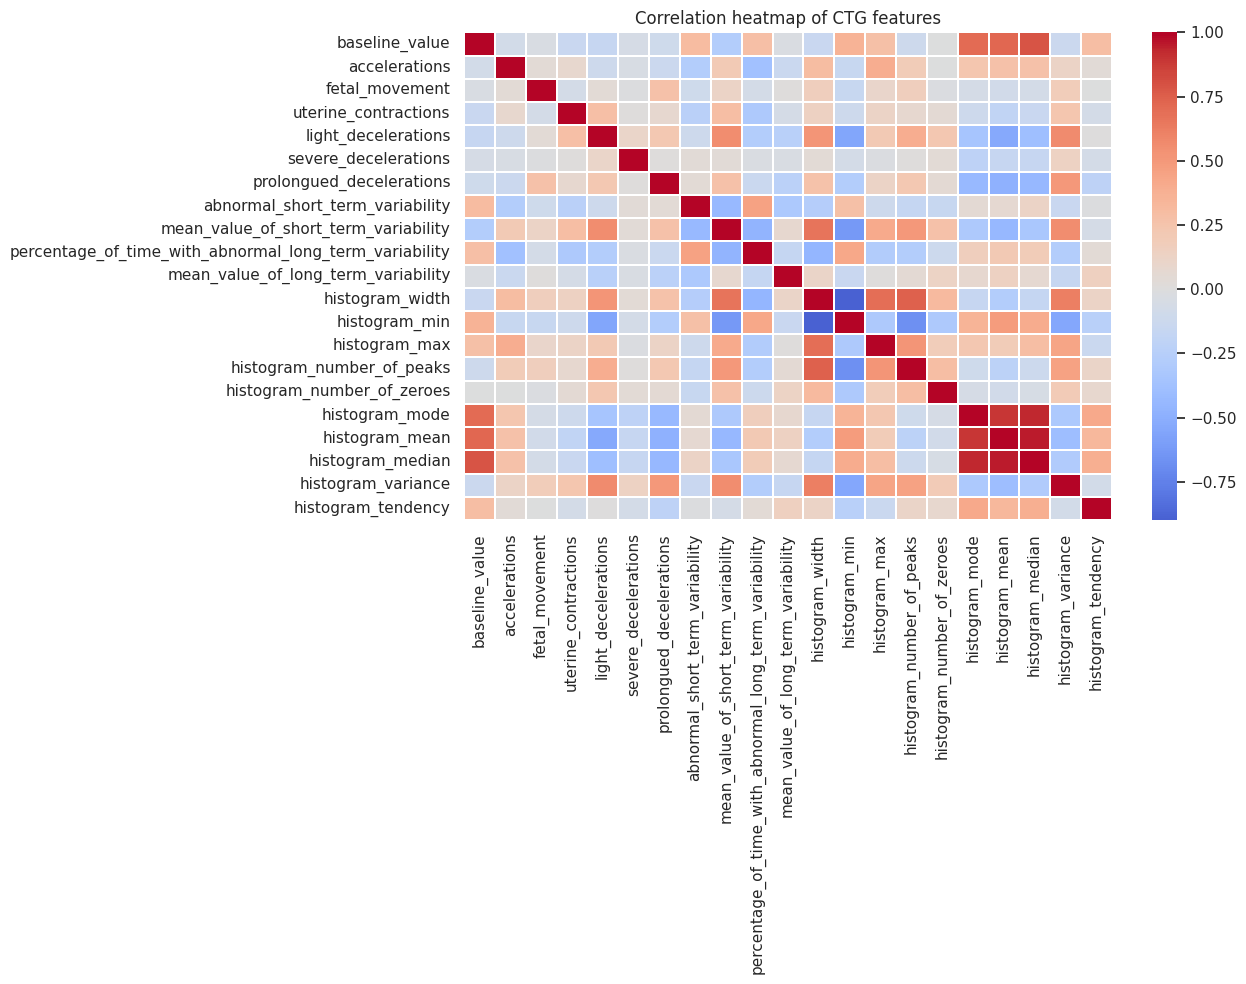

In [12]:
plt.figure(figsize=(13, 10))
sns.heatmap(df.drop(columns="fetal_health").corr(), cmap="coolwarm", center=0, annot=False, linewidths=.3)
plt.title("Correlation heatmap of CTG features"); plt.tight_layout()
plt.savefig("figs/04_correlation_heatmap.png", dpi=150); plt.show()
print(df.drop(columns="fetal_health").corr().abs().where(np.triu(np.ones((21,21)),1).astype(bool))
        .stack().sort_values(ascending=False).head(5).round(2))

**Interpretation.** The histogram summary features are heavily **redundant**: `histogram_mean`, `histogram_median` and `histogram_mode` are strongly correlated (r ≈ 0.95 between mean and median), and `histogram_width` with `histogram_min` (r ≈ 0.90). Keeping all of them adds noise and instability, especially for Logistic Regression, so I keep only one or two per group during feature selection.

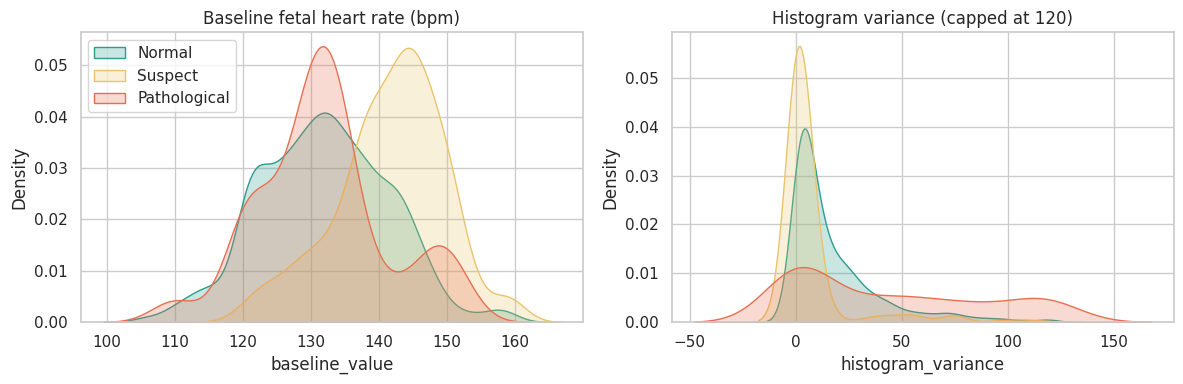

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for cls, col in zip([1,2,3], ["#2a9d8f","#e9c46a","#e76f51"]):
    sns.kdeplot(df[df.fetal_health==cls].baseline_value, ax=ax[0], label=CLASS_NAMES[cls], color=col, fill=True, alpha=.25)
    sns.kdeplot(df[df.fetal_health==cls].histogram_variance.clip(upper=120), ax=ax[1], label=CLASS_NAMES[cls], color=col, fill=True, alpha=.25)
ax[0].set_title("Baseline fetal heart rate (bpm)"); ax[1].set_title("Histogram variance (capped at 120)")
ax[0].legend(); plt.tight_layout(); plt.savefig("figs/05_baseline_variance.png", dpi=150); plt.show()

**Interpretation.** Baseline heart rate overlaps heavily across the three classes: it shifts slightly higher for Pathological cases but cannot separate them alone. Mean histogram variance is lowest for Suspect (about 7) and highest for Pathological recordings (about 51, versus about 18 for Normal), so the classes differ in *how much* the heart rate varies, not just its average level. This supports using **combinations** of variables rather than any single one.

## 4. Scaling the Data
`StandardScaler` is **fitted on the training data only**; the same learned mean/standard deviation is then applied to the test data, so the test set stays an unseen, realistic sample.

In [14]:
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=X.columns, index=X_test.index)
X_train_s.describe().loc[["mean","std"]].round(2).iloc[:, :6]

,baseline_value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations
mean,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


## 5. Data Balancing with SMOTE
SMOTE creates *synthetic* minority-class samples by interpolating between a minority point and its nearest neighbours. Because it relies on distances, it is applied to the **scaled** training data. **Only the training set is balanced**; the test set stays untouched so that evaluation reflects real-world class proportions.

Before SMOTE: {1: 1316, 2: 234, 3: 140}
After  SMOTE: {1: 1316, 2: 1316, 3: 1316}


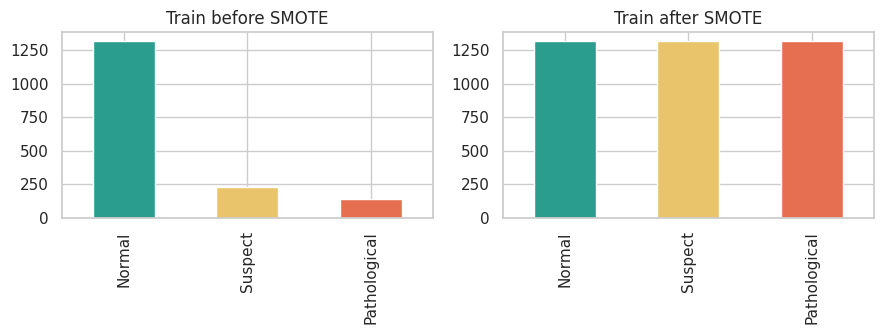

In [15]:
def smote_resample(Xa, ya, k=5, seed=RS):
    """SMOTE via imbalanced-learn when installed (pip install imbalanced-learn);
    otherwise an equivalent built-in implementation (k-NN interpolation)."""
    try:
        from imblearn.over_sampling import SMOTE
        Xr, yr = SMOTE(random_state=seed, k_neighbors=k).fit_resample(Xa, ya)
        return pd.DataFrame(Xr, columns=Xa.columns), pd.Series(yr, name=ya.name)
    except ImportError:
        cols = list(Xa.columns); rng = np.random.RandomState(seed); A = np.asarray(Xa); b = np.asarray(ya)
        n_max = pd.Series(b).value_counts().max(); Xs, ys = [A], [b]
        for c in np.unique(b):
            Ac = A[b == c]; need = n_max - len(Ac)
            if need <= 0: continue
            idx = NearestNeighbors(n_neighbors=k+1).fit(Ac).kneighbors(Ac, return_distance=False)[:, 1:]
            i = rng.randint(0, len(Ac), need); j = idx[i, rng.randint(0, k, need)]
            Xs.append(Ac[i] + rng.rand(need, 1) * (Ac[j] - Ac[i])); ys.append(np.full(need, c))
        return pd.DataFrame(np.vstack(Xs), columns=cols), pd.Series(np.concatenate(ys), name="fetal_health")

X_bal, y_bal = smote_resample(X_train_s, y_train)
print("Before SMOTE:", y_train.value_counts().sort_index().to_dict())
print("After  SMOTE:", y_bal.value_counts().sort_index().to_dict())
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5), sharey=False)
for a, s, t in zip(ax, [y_train, y_bal], ["Train before SMOTE", "Train after SMOTE"]):
    s.map(CLASS_NAMES).value_counts().reindex(["Normal","Suspect","Pathological"]).plot.bar(ax=a, color=["#2a9d8f","#e9c46a","#e76f51"]); a.set_title(t); a.set_xlabel("")
plt.tight_layout(); plt.savefig("figs/06_smote.png", dpi=150); plt.show()

**Interpretation.** The training set went from 1316 / 234 / 140 to **1316 / 1316 / 1316**, so the models see the Suspect and Pathological classes as often as Normal and will not simply favour the majority class. All work from here uses this balanced training set.

## 6. Feature Selection
An interim **Random Forest** ranks the features by importance, and the choice is then checked against **domain knowledge** and the correlation analysis:
1. Keep features whose importance is above a small threshold (≥ 0.035).
2. Drop `histogram_median` because it duplicates `histogram_mean` (r = 0.95), a redundancy rather than new information.
3. Features with near-zero importance (`severe_decelerations`, `histogram_number_of_zeroes`, `histogram_tendency`, `light_decelerations`) are dropped because they are almost always 0 or constant in this data.

10 selected features:
abnormal_short_term_variability
percentage_of_time_with_abnormal_long_term_variability
histogram_mean
mean_value_of_short_term_variability
accelerations
prolongued_decelerations
histogram_mode
mean_value_of_long_term_variability
baseline_value
histogram_variance


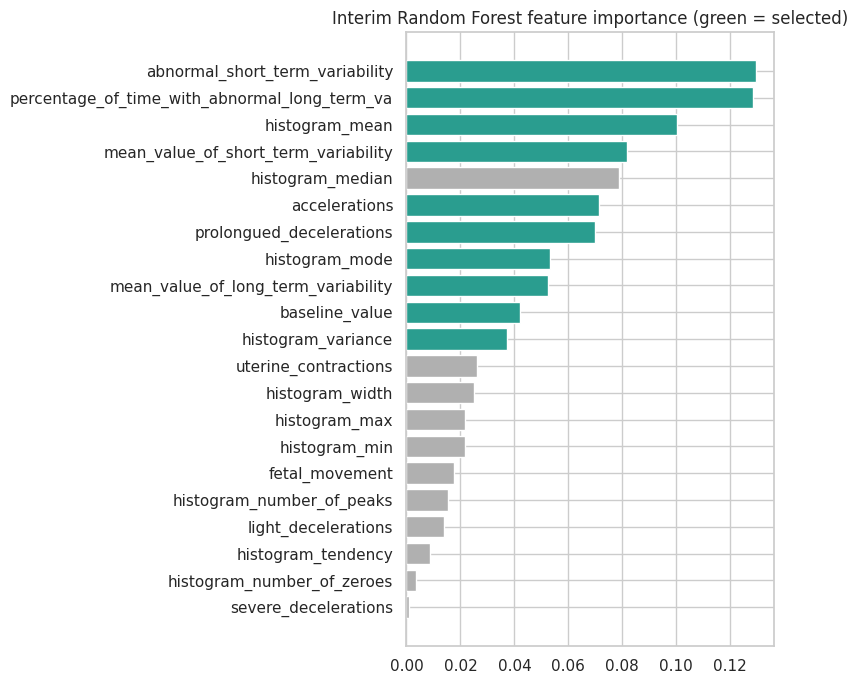

In [16]:
rf_sel = RandomForestClassifier(n_estimators=300, random_state=RS, n_jobs=-1).fit(X_bal, y_bal)
imp = pd.Series(rf_sel.feature_importances_, index=X.columns).sort_values(ascending=False)
selected = [f for f in imp.index if imp[f] >= 0.035 and f != "histogram_median"]

fig, ax = plt.subplots(figsize=(8, 7))
colors = ["#2a9d8f" if f in selected else "#b0b0b0" for f in imp.index]
ax.barh([f[:45] for f in imp.index][::-1], imp.values[::-1], color=colors[::-1])
ax.set_title("Interim Random Forest feature importance (green = selected)"); plt.tight_layout()
plt.savefig("figs/07_feature_selection.png", dpi=150); plt.show()
print(len(selected), "selected features:"); print(*selected, sep="\n")
X_bal_f, X_test_f = X_bal[selected], X_test_s[selected]

**Interpretation.** The most informative features are **abnormal short-term variability**, **% time with abnormal long-term variability**, **histogram mean**, **short-term variability**, **accelerations** and **prolonged decelerations**. These match the clinical meaning of CTG reading. The final model uses **10 features** instead of 21, which makes it simpler and easier to deploy: a user only has to enter 10 values.

## 7. Model Building and Evaluation
Four algorithms are trained on the balanced, selected-feature training data: **Logistic Regression**, **K-Nearest Neighbours**, **Random Forest** and **Gradient Boosting** (XGBoost-style boosted trees). Each is also evaluated with **5-fold stratified cross-validation**, where SMOTE is re-applied *inside every fold's training part only* so the validation fold stays real and no synthetic points leak in.

In [17]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RS),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RS, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RS),
}
skf = StratifiedKFold(5, shuffle=True, random_state=RS)
def cv_macro_f1(model, Xs, ys, cols):
    scores = []
    for tr, va in skf.split(Xs, ys):
        Xa, ya = smote_resample(Xs.iloc[tr][cols], ys.iloc[tr])
        m = model.__class__(**model.get_params()).fit(Xa, ya)
        scores.append(f1_score(ys.iloc[va], m.predict(Xs.iloc[va][cols]), average="macro"))
    return np.mean(scores), np.std(scores)

rows, fitted = [], {}
for name, m in models.items():
    cv_m, cv_s = cv_macro_f1(m, X_train_s, y_train, selected)
    m.fit(X_bal_f, y_bal); fitted[name] = m
    p, pr = m.predict(X_test_f), m.predict_proba(X_test_f)
    rows.append({"Model": name, "CV macro-F1": cv_m, "Accuracy": accuracy_score(y_test, p),
                 "Macro Precision": precision_score(y_test, p, average="macro"),
                 "Macro Recall": recall_score(y_test, p, average="macro"),
                 "Macro F1": f1_score(y_test, p, average="macro"),
                 "Pathological Recall": recall_score(y_test, p, labels=[3], average="macro"),
                 "ROC-AUC (OvR)": roc_auc_score(y_test, pr, multi_class="ovr", average="macro")})
results = pd.DataFrame(rows).set_index("Model").round(3)
results

,CV macro-F1,Accuracy,Macro Precision,Macro Recall,Macro F1,Pathological Recall,ROC-AUC (OvR)
Model,,,,,,,
Logistic Regression,0.778,0.870,0.757,0.809,0.779,0.800,0.953
KNN,0.832,0.910,0.815,0.898,0.850,0.914,0.959
Random Forest,0.888,0.939,0.905,0.894,0.899,0.971,0.986
Gradient Boosting,0.876,0.943,0.910,0.910,0.910,0.971,0.979


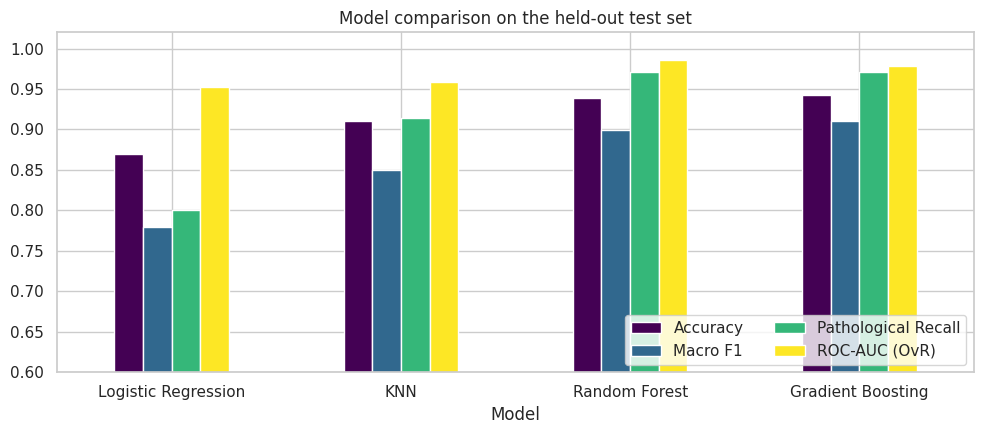

In [18]:
ax = results[["Accuracy","Macro F1","Pathological Recall","ROC-AUC (OvR)"]].plot.bar(figsize=(10, 4.5), rot=0, colormap="viridis")
ax.set_ylim(0.6, 1.02); ax.set_title("Model comparison on the held-out test set"); ax.legend(loc="lower right", ncol=2)
plt.tight_layout(); plt.savefig("figs/08_model_comparison.png", dpi=150); plt.show()

**Interpretation.** The two tree ensembles clearly beat the simpler models. **Random Forest** and **Gradient Boosting** reach ~94% test accuracy, macro-F1 around 0.90–0.91, and ~97% recall on Pathological cases. **Logistic Regression** is weakest (macro-F1 ≈ 0.78), because the relationship between CTG measurements and fetal health is non-linear (thresholds and interactions). KNN sits in between. **Random Forest** has the best cross-validated macro-F1 (0.888) and the highest ROC-AUC (≈ 0.986), so it is chosen as the model to tune and deploy. Gradient Boosting is a very close second.

### 7.1 Variable importance from all models

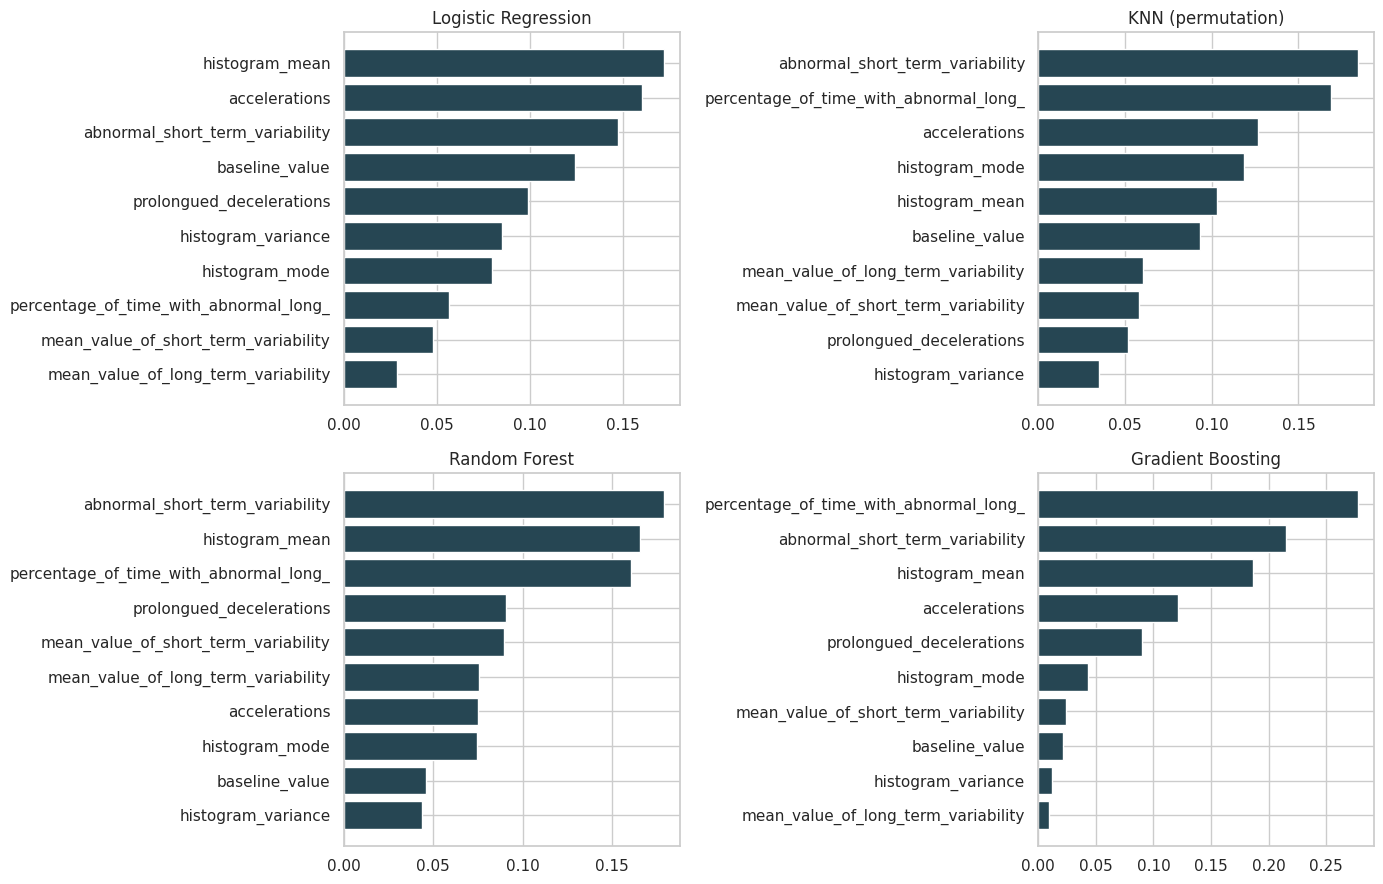

,Logistic Regression,KNN (permutation),Random Forest,Gradient Boosting,Mean
abnormal_short_term_variability,0.147,0.184,0.179,0.215,0.181
percentage_of_time_with_abnormal_long_term_variability,0.056,0.169,0.161,0.278,0.166
histogram_mean,0.172,0.103,0.165,0.186,0.157
accelerations,0.160,0.127,0.075,0.121,0.121
prolongued_decelerations,0.099,0.052,0.091,0.090,0.083
histogram_mode,0.080,0.119,0.075,0.043,0.079
baseline_value,0.124,0.093,0.046,0.022,0.071
mean_value_of_short_term_variability,0.048,0.058,0.090,0.024,0.055
histogram_variance,0.085,0.035,0.043,0.012,0.044
mean_value_of_long_term_variability,0.028,0.061,0.075,0.009,0.043


In [19]:
perm = permutation_importance(fitted["KNN"], X_test_f, y_test, scoring="f1_macro", n_repeats=10, random_state=RS)
imps = pd.DataFrame({
    "Logistic Regression": np.abs(fitted["Logistic Regression"].coef_).mean(axis=0),
    "KNN (permutation)": perm.importances_mean,
    "Random Forest": fitted["Random Forest"].feature_importances_,
    "Gradient Boosting": fitted["Gradient Boosting"].feature_importances_}, index=selected)
imps_n = imps / imps.sum()          # make each model sum to 1 so they are comparable
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for a, c in zip(axes.ravel(), imps_n.columns):
    s = imps_n[c].sort_values(); a.barh([i[:38] for i in s.index], s.values, color="#264653"); a.set_title(c)
plt.tight_layout(); plt.savefig("figs/09_variable_importance.png", dpi=150); plt.show()
imps_n.round(3).assign(Mean=imps_n.mean(axis=1)).sort_values("Mean", ascending=False).round(3)

**Interpretation.** Averaged over the four models, the top drivers are `abnormal_short_term_variability`, `percentage_of_time_with_abnormal_long_term_variability`, `histogram_mean`, `accelerations` and `prolongued_decelerations`. The tree models (Random Forest, Gradient Boosting) lean mostly on the two variability measures, while Logistic Regression relies more on `histogram_mean`, `accelerations` and `baseline_value`. The signals a clinician watches (variability, accelerations, decelerations) are what the models rely on, which makes the predictions clinically sensible and easier to trust.

### 7.2 Hyper-parameter tuning of the best model (Random Forest, cross-validated)

In [20]:
grid = {"n_estimators": [200, 400], "max_depth": [None, 12, 20], "min_samples_leaf": [1, 2]}
gs = GridSearchCV(RandomForestClassifier(random_state=RS, n_jobs=-1), grid, cv=3, scoring="f1_macro").fit(X_bal_f, y_bal)
best = gs.best_estimator_
print("Best parameters:", gs.best_params_)
print("Best CV macro-F1 (on balanced train):", round(gs.best_score_, 3))

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Best CV macro-F1 (on balanced train): 0.971


### 7.3 Final evaluation on the untouched test set: classification report, confusion matrix and ROC-AUC

In [21]:
pred, proba = best.predict(X_test_f), best.predict_proba(X_test_f)
print(classification_report(y_test, pred, target_names=list(CLASS_NAMES.values())))
print("Accuracy:", round(accuracy_score(y_test, pred), 3), "| Macro F1:", round(f1_score(y_test, pred, average='macro'), 3),
      "| ROC-AUC (OvR macro):", round(roc_auc_score(y_test, proba, multi_class='ovr'), 3))

              precision    recall  f1-score   support

      Normal       0.96      0.97      0.97       330
     Suspect       0.83      0.74      0.78        58
Pathological       0.94      0.97      0.96        35

    accuracy                           0.94       423
   macro avg       0.91      0.90      0.90       423
weighted avg       0.94      0.94      0.94       423

Accuracy: 0.941 | Macro F1: 0.902 | ROC-AUC (OvR macro): 0.985


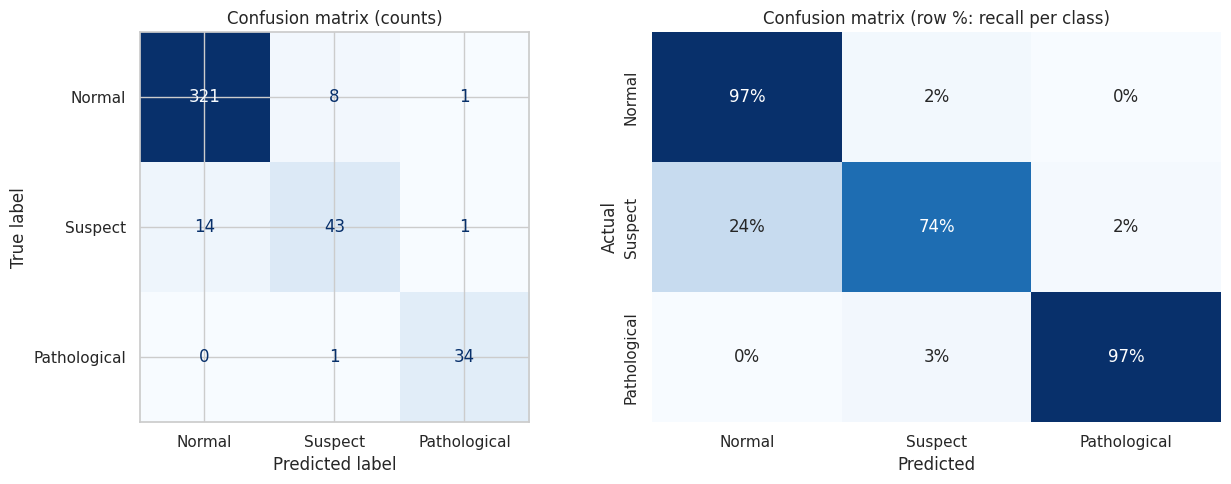

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=list(CLASS_NAMES.values())).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (counts)")
cmn = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cmn, annot=True, fmt=".0%", cmap="Blues", cbar=False, xticklabels=CLASS_NAMES.values(), yticklabels=CLASS_NAMES.values(), ax=ax[1])
ax[1].set_title("Confusion matrix (row %: recall per class)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual")
plt.tight_layout(); plt.savefig("figs/10_confusion_matrix.png", dpi=150); plt.show()

**Reading the confusion matrix.** Of 35 truly **Pathological** test cases, **34 were caught** (≈ 97% recall) and only one was labelled Suspect, with none missed as Normal. Of 330 **Normal** cases, 321 were correct. The main weakness is the **Suspect** class: about a quarter of Suspect cases (14 of 58) were labelled Normal. This is expected because Suspect is the borderline zone between Normal and Pathological, so its pattern overlaps with both neighbours. Importantly, the most dangerous error (a Pathological case predicted Normal) did not occur in the test set.

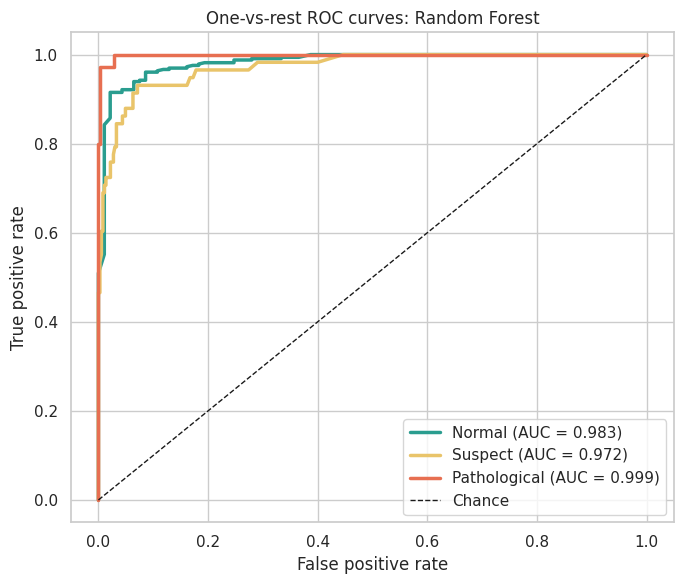

In [23]:
Y = label_binarize(y_test, classes=[1, 2, 3])
plt.figure(figsize=(7, 6))
for i, (cls, col) in enumerate(zip([1,2,3], ["#2a9d8f","#e9c46a","#e76f51"])):
    fpr, tpr, _ = roc_curve(Y[:, i], proba[:, i]); plt.plot(fpr, tpr, color=col, lw=2.5, label=f"{CLASS_NAMES[cls]} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0,1],[0,1],"k--", lw=1, label="Chance"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("One-vs-rest ROC curves: Random Forest"); plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig("figs/11_roc_curves.png", dpi=150); plt.show()

**Reading the ROC curves.** Every curve hugs the top-left corner: the AUC is **0.999 for Pathological**, **0.983 for Normal** and **0.972 for Suspect**, against 0.5 for random guessing. For every class, the model ranks a randomly chosen positive case above a randomly chosen negative one at least 97% of the time. The slightly lower Suspect AUC matches what the confusion matrix showed: that class is the hardest to separate.

## 8. Save the model for deployment (Streamlit app)

In [24]:
bundle = {"model": best, "features": selected,
          "mean": dict(zip(X.columns, scaler.mean_)), "scale": dict(zip(X.columns, scaler.scale_)),
          "clip_lo": lo.to_dict(), "clip_hi": hi.to_dict(),
          "ranges": {f: (float(df[f].min()), float(df[f].max()), float(df[f].median())) for f in selected},
          "classes": CLASS_NAMES}
joblib.dump(bundle, "fetal_health_model.joblib")
print("Saved fetal_health_model.joblib")

Saved fetal_health_model.joblib


## 9. Conclusion and Recommendations
**Conclusion.** After cleaning (13 duplicates removed), leak-free scaling, SMOTE balancing of the training set only and selection of 10 clinically meaningful features, a tuned **Random Forest** classified CTG recordings with ≈ 94% accuracy, macro-F1 ≈ 0.90 and macro ROC-AUC ≈ 0.985 on unseen data. It detected **97% of Pathological cases**, and no Pathological case was predicted as Normal.

**Recommendations.**
1. Use the model as **decision support to flag recordings for urgent review**, not as a replacement for a clinician, especially in clinics without trained CTG readers.
2. Treat **Suspect** predictions with extra caution: this is the least reliable class, so any Suspect or Pathological probability should trigger human follow-up.
3. Train staff to focus on the strongest signals the model uses: abnormal short/long-term variability, prolonged decelerations and absent accelerations.
4. Before real clinical use, **validate on local data** (this dataset's population may differ), collect more Suspect/Pathological cases and monitor performance over time.
5. Future work: try XGBoost/LightGBM, probability calibration and threshold tuning to push Pathological recall even higher.

*Limitations: a single dataset, a single train/test split plus cross-validation, and synthetic (SMOTE) samples in training. Results are a prototype, not a certified medical device.*